# Fase B — Limpieza y Normalización
Pipeline completo desde el CSV crudo hasta `datos_limpios.parquet`. Cada decisión se justifica en la celda correspondiente.

**Orden del pipeline:** diagnóstico → corrección de texto y llaves → tipos → nulos → outliers → variables derivadas → transformación de sesgo → encoding → (escalado: se demuestra aquí, pero se **ajusta en la Fase C después del split** para evitar data leakage) → guardado.

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
os.makedirs("figuras", exist_ok=True)
def guardar(nombre):
    plt.savefig(f"figuras/{nombre}.png", dpi=130, bbox_inches="tight")

RUTA = os.environ.get("DATA_PATH") or glob.glob("../MEN_ESTADISTICAS*.csv")[0]
raw = pd.read_csv(RUTA, dtype=str)
ID_COLS = ["AÑO", "CÓDIGO_MUNICIPIO", "MUNICIPIO", "CÓDIGO_DEPARTAMENTO", "DEPARTAMENTO", "CÓDIGO_ETC", "ETC"]
NUM_COLS = [c for c in raw.columns if c not in ID_COLS]
print(raw.shape)

(15707, 41)


## 1. Diagnóstico

### 1.1 Nulos

In [2]:
nulos = raw.isna().sum().to_frame("nulos")
nulos["%"] = (nulos["nulos"] / len(raw) * 100).round(2)
nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)

,nulos,%
TAMAÑO_PROMEDIO_DE_GRUPO,8135,51.79
SEDES_CONECTADAS_A_INTERNET,7939,50.54
DESERCIÓN_TRANSICIÓN,903,5.75
DESERCIÓN_MEDIA,734,4.67
DESERCIÓN_SECUNDARIA,270,1.72
DESERCIÓN_PRIMARIA,242,1.54
REPITENCIA_TRANSICIÓN,159,1.01
REPITENCIA_SECUNDARIA,152,0.97
REPITENCIA_PRIMARIA,148,0.94
REPROBACIÓN_MEDIA,145,0.92


In [3]:
# ¿Los nulos de TAMAÑO_PROMEDIO_DE_GRUPO y SEDES son aleatorios o estructurales?
raw.groupby("AÑO")[["TAMAÑO_PROMEDIO_DE_GRUPO", "SEDES_CONECTADAS_A_INTERNET"]].count().T

AÑO,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
TAMAÑO_PROMEDIO_DE_GRUPO,1107,1107,932,1106,1107,1106,1107,0,0,0,0,0,0,0
SEDES_CONECTADAS_A_INTERNET,1117,1117,1119,1118,1120,1095,1082,0,0,0,0,0,0,0


### 1.2 Duplicados e inconsistencias de texto

In [4]:
print("Duplicados exactos:", raw.duplicated().sum())
print("Longitud de CÓDIGO_MUNICIPIO:", raw["CÓDIGO_MUNICIPIO"].str.len().value_counts().to_dict())
print("Códigos únicos tal como vienen:", raw["CÓDIGO_MUNICIPIO"].nunique(), "| con relleno a 5 dígitos:", raw["CÓDIGO_MUNICIPIO"].str.zfill(5).nunique())
print("Filas agregadas 'NACIONAL':", (raw["DEPARTAMENTO"] == "NACIONAL").sum())
nombres = raw.groupby(raw["CÓDIGO_DEPARTAMENTO"].str.zfill(2))["DEPARTAMENTO"].unique()
print("Departamentos con más de un nombre:"); print(nombres[nombres.str.len() > 1].to_string())
mun = raw.groupby(raw["CÓDIGO_MUNICIPIO"].str.zfill(5))["MUNICIPIO"].unique()
print("Municipios con más de un nombre:"); print(mun[mun.str.len() > 1].to_string())
print("Espacios sobrantes en MUNICIPIO:", (raw["MUNICIPIO"] != raw["MUNICIPIO"].str.strip()).sum())
print("Valores con formato %:", raw["DESERCIÓN"].dropna().head(3).tolist())
pob = raw["POBLACIÓN_5_16"].fillna("")
print("POBLACIÓN con separador de miles '.':", pob.str.contains(r"\.").sum(), "→ años", raw.loc[pob.str.contains(r"\."), "AÑO"].unique().tolist(), "| ejemplos:", pob[pob.str.contains(r"[.,]")].head(4).tolist())

Duplicados exactos: 0
Longitud de CÓDIGO_MUNICIPIO: {5: 13928, 4: 1776, 1: 3}
Códigos únicos tal como vienen: 1272 | con relleno a 5 dígitos: 1124
Filas agregadas 'NACIONAL': 3
Departamentos con más de un nombre:
CÓDIGO_DEPARTAMENTO
11                          [Bogotá, D.C., Bogotá D.C.]
88    [Archipiélago de San Andrés, Providencia y San...
Municipios con más de un nombre:
CÓDIGO_MUNICIPIO
11001    [Bogotá, D.C., Bogotá D.C.]
Espacios sobrantes en MUNICIPIO: 0
Valores con formato %: ['0%', '3,24%', '5,5%']
POBLACIÓN con separador de miles '.': 925 → años ['2021'] | ejemplos: ['24.934', '1.148', '2.503', '4.598']


**Diagnóstico:**
- No hay duplicados exactos, pero el código DANE del municipio llega **sin el cero inicial** en una parte de los registros (`5004` vs `05004`), lo que partiría a un mismo municipio en dos. Se rellena a 5 dígitos (2 para departamento).
- Existen filas **`NACIONAL`** (agregado del país), que no son municipios y distorsionarían cualquier modelo: se eliminan.
- Bogotá y San Andrés aparecen con dos escrituras distintas y `Quindio` sin tilde: se normaliza el nombre usando el código DANE como llave.
- Todas las tasas son texto con `%` y coma decimal: se convierten a `float`.
- **`POBLACIÓN_5_16` de 2021 viene con punto como separador de miles** (`"1.148"` = 1.148 niños, `"3.89"` = 3.890 porque se perdió el cero final; Bogotá con comas `"1,174,274"`). Una conversión ingenua la leería como 1,148 habitantes y arruinaría el tamaño del municipio para todo ese año.

## 2. Corrección de llaves, texto y tipos

In [5]:
df = raw[raw["DEPARTAMENTO"] != "NACIONAL"].copy()
df["CÓDIGO_MUNICIPIO"] = df["CÓDIGO_MUNICIPIO"].str.zfill(5)
df["CÓDIGO_DEPARTAMENTO"] = df["CÓDIGO_DEPARTAMENTO"].str.zfill(2)
for c in ["MUNICIPIO", "DEPARTAMENTO", "ETC"]:
    df[c] = df[c].str.strip()

NOMBRE_DEPTO = {"11": "Bogotá D.C.", "88": "San Andrés y Providencia", "63": "Quindío"}
df["DEPARTAMENTO"] = df["CÓDIGO_DEPARTAMENTO"].map(NOMBRE_DEPTO).fillna(df["DEPARTAMENTO"])
df.loc[df["CÓDIGO_MUNICIPIO"] == "11001", "MUNICIPIO"] = "Bogotá D.C."

def poblacion_a_numero(s):
    # 2021 llega con separador de miles: "1.148" = 1148, "3.89" = 3890 (perdió el cero final), Bogotá "1,174,274"
    partes = s.str.replace(",", ".", regex=False).str.split(".")
    return pd.to_numeric(partes.map(lambda p: p[0] + "".join(x.ljust(3, "0") for x in p[1:]), na_action="ignore"), errors="coerce")

assert poblacion_a_numero(pd.Series(["1.148", "3.89", "1,174,274", "499"])).tolist() == [1148, 3890, 1174274, 499]
df["POBLACIÓN_5_16"] = poblacion_a_numero(df["POBLACIÓN_5_16"])
for c in NUM_COLS[1:]:  # tasas: "56,11%" → 56.11
    df[c] = pd.to_numeric(df[c].str.replace("%", "", regex=False).str.replace(",", ".", regex=False), errors="coerce")
df["AÑO"] = df["AÑO"].astype(int)

print("Duplicados por llave (AÑO, CÓDIGO_MUNICIPIO):", df.duplicated(["AÑO", "CÓDIGO_MUNICIPIO"]).sum())
print("Departamentos:", df["DEPARTAMENTO"].nunique(), "| Municipios:", df["CÓDIGO_MUNICIPIO"].nunique(), "| Filas:", len(df))

Duplicados por llave (AÑO, CÓDIGO_MUNICIPIO): 0
Departamentos: 33 | Municipios: 1123 | Filas: 15704


## 3. Tratamiento de nulos

**Decisiones por columna:**

| Columna(s) | Estrategia | Justificación |
|---|---|---|
| `TAMAÑO_PROMEDIO_DE_GRUPO`, `SEDES_CONECTADAS_A_INTERNET` | **Eliminar columna** | ~50 % nulos y el faltante es **estructural** (no se reporta desde 2018). Imputar 7 años completos sería inventar datos. |
| `DESERCIÓN` (objetivo) | **Eliminar fila** | No se imputa la variable objetivo: imputarla crea etiquetas falsas que el modelo aprendería. |
| `POBLACIÓN_5_16` | **Mediana del mismo municipio** en otros años | La población cambia poco entre años; la mediana del propio municipio es mucho mejor que la nacional (Bogotá vs. un municipio de 500 niños). |
| Coberturas (`TASA_MATRICULACIÓN`, `COBERTURA_NETA_*`, `COBERTURA_BRUTA_*`) | **KNN (k = 5)** — *ajustado solo con train, dentro del Pipeline* | Las coberturas están muy correlacionadas entre sí (ρ > 0.8); KNN aprovecha los otros niveles del mismo registro para estimar el faltante. |
| `REPROBACIÓN_*`, `REPITENCIA_*` | **Mediana** — *ajustada solo con train, dentro del Pipeline* | Distribuciones con fuerte asimetría positiva y outliers: la media se desplaza hacia la cola, la mediana no. |
| `APROBACIÓN_*`, `DESERCIÓN_*` por nivel | **Mediana** aquí mismo | No son features de ningún modelo (son la identidad contable y los componentes del objetivo); solo se usan de forma descriptiva. |

**Para evitar fuga de información (data leakage)**, KNN y la mediana de las features **no se ajustan aquí con todo el dataset**: el parquet guarda esos nulos (< 1 % por columna) y el imputador se ajusta **solo con el conjunto de entrenamiento**, dentro del `Pipeline` reproducible de la Fase C (sección 8 de este notebook lo demuestra). La población se completa con la mediana **del propio municipio**: es un atributo fijo del municipio (proyección DANE), no un estadístico aprendido del conjunto.

No hay nulos en las categóricas, por lo que no fue necesaria la moda.

In [6]:
df = df.drop(columns=["TAMAÑO_PROMEDIO_DE_GRUPO", "SEDES_CONECTADAS_A_INTERNET"])
n0 = len(df); df = df.dropna(subset=["DESERCIÓN"]); print("Filas eliminadas por objetivo nulo:", n0 - len(df))

# Registros sin actividad: cobertura bruta 0 % en un municipio con población no es un dato real (municipios aún no creados o sin reporte)
sin_dato = df["COBERTURA_BRUTA"].eq(0)
print("Filas con cobertura bruta = 0 % (eliminadas):", sin_dato.sum()); df = df[~sin_dato]

df["POBLACIÓN_5_16"] = df["POBLACIÓN_5_16"].fillna(df.groupby("CÓDIGO_MUNICIPIO")["POBLACIÓN_5_16"].transform("median"))

DESC_COLS = [c for c in df.columns if c.startswith(("APROBACIÓN", "DESERCIÓN_"))]  # solo descriptivas
df[DESC_COLS] = df[DESC_COLS].fillna(df[DESC_COLS].median())

# Columnas que se imputan en el Pipeline (KNN = coberturas, mediana = reprobación/repitencia)
COB_COLS = [c for c in df.columns if c.startswith(("COBERTURA", "TASA_MATRICULACIÓN"))]
MED_COLS = [c for c in df.columns if c.startswith(("REPROBACIÓN", "REPITENCIA"))]
pendientes = df.isna().sum()
assert set(pendientes[pendientes > 0].index) <= set(COB_COLS + MED_COLS), "Quedaron nulos fuera de las columnas del Pipeline"
print("Filas:", len(df), "| Nulos que se imputarán en el Pipeline (solo con train):")
print(pendientes[pendientes > 0].to_string())

Filas eliminadas por objetivo nulo: 142
Filas con cobertura bruta = 0 % (eliminadas): 4
Filas: 15558 | Nulos que se imputarán en el Pipeline (solo con train):
TASA_MATRICULACIÓN_5_16        82
COBERTURA_NETA                 79
COBERTURA_NETA_TRANSICIÓN      31
COBERTURA_NETA_PRIMARIA        62
COBERTURA_NETA_SECUNDARIA      58
COBERTURA_NETA_MEDIA           51
COBERTURA_BRUTA                41
COBERTURA_BRUTA_TRANSICIÓN     75
COBERTURA_BRUTA_PRIMARIA       57
COBERTURA_BRUTA_SECUNDARIA     59
COBERTURA_BRUTA_MEDIA          85
REPROBACIÓN                    58
REPROBACIÓN_TRANSICIÓN         56
REPROBACIÓN_PRIMARIA           64
REPROBACIÓN_SECUNDARIA         79
REPROBACIÓN_MEDIA             120
REPITENCIA                    114
REPITENCIA_TRANSICIÓN         123
REPITENCIA_PRIMARIA           120
REPITENCIA_SECUNDARIA         124
REPITENCIA_MEDIA              109


## 4. Outliers (IQR)

In [7]:
TASAS = ["DESERCIÓN", "REPROBACIÓN", "REPITENCIA", "COBERTURA_NETA", "COBERTURA_BRUTA", "COBERTURA_NETA_MEDIA", "POBLACIÓN_5_16"]
def limites_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr
tabla = []
for c in TASAS:
    lo, hi = limites_iqr(df[c]); n = ((df[c] < lo) | (df[c] > hi)).sum()
    tabla.append([c, round(lo, 2), round(hi, 2), n, f"{n / len(df):.1%}"])
pd.DataFrame(tabla, columns=["variable", "lím_inf", "lím_sup", "outliers", "%"])

,variable,lím_inf,lím_sup,outliers,%
0,DESERCIÓN,-2.08,8.67,377,2.4%
1,REPROBACIÓN,-8.09,16.76,101,0.6%
2,REPITENCIA,-6.71,13.34,245,1.6%
3,COBERTURA_NETA,49.92,120.92,672,4.3%
4,COBERTURA_BRUTA,49.99,143.83,551,3.5%
5,COBERTURA_NETA_MEDIA,2.81,79.50,282,1.8%
6,POBLACIÓN_5_16,-5899.50,13662.50,1480,9.5%


In [8]:
lo, hi = limites_iqr(df["DESERCIÓN"])
df.loc[df["DESERCIÓN"] > hi, ["AÑO", "MUNICIPIO", "DEPARTAMENTO", "POBLACIÓN_5_16", "DESERCIÓN"]].sort_values("DESERCIÓN", ascending=False).head(10)

,AÑO,MUNICIPIO,DEPARTAMENTO,POBLACIÓN_5_16,DESERCIÓN
3380,2021,Morichal,Guainía,332.0,27.90
3869,2021,Hobo,Huila,1668.0,16.63
2259,2022,La Guadalupe,Guainía,111.0,16.25
3381,2021,Pana Pana,Guainía,650.0,16.21
2236,2023,San Felipe,Guainía,671.0,16.00
9333,2016,Morichal,Guainía,387.0,15.53
7839,2018,La Guadalupe,Guainía,104.0,15.52
7860,2017,Pacoa,Vaupés,1725.0,15.29
3408,2021,Puerto Guzmán,Putumayo,9907.0,15.22
4593,2020,Ansermanuevo,Valle del Cauca,3713.0,15.21


**Decisión: se CONSERVAN los outliers.**
- Son municipios reales (Bogotá, Medellín, Cali en población; municipios de Amazonía, Orinoquía o Chocó en deserción). Precisamente los municipios con deserción extrema son **los que el negocio quiere detectar**: eliminarlos borraría la señal.
- Coberturas > 100 % son válidas según la metodología del MEN (extraedad y desfase de proyecciones DANE).
- Su efecto se controla con (1) transformación logarítmica de las variables sesgadas, (2) modelos de árboles, robustos a valores extremos, y (3) escalado ajustado solo con train.
- Solo se eliminaron los registros **imposibles** (cobertura bruta = 0 %), que son errores, no outliers.

## 5. Variables derivadas

In [9]:
REGION = {**dict.fromkeys(["08", "13", "20", "23", "44", "47", "70"], "Caribe"), "88": "Insular",
          **dict.fromkeys(["19", "27", "52", "76"], "Pacífica"),
          **dict.fromkeys(["05", "11", "15", "17", "25", "41", "54", "63", "66", "68", "73"], "Andina"),
          **dict.fromkeys(["50", "81", "85", "99"], "Orinoquía"),
          **dict.fromkeys(["18", "86", "91", "94", "95", "97"], "Amazonía")}
df["REGION"] = df["CÓDIGO_DEPARTAMENTO"].map(REGION)
assert df["REGION"].notna().all()

ORDEN_TAMAÑO = ["Muy pequeño", "Pequeño", "Mediano", "Grande"]
df["TAMAÑO_MUNICIPIO"] = pd.cut(df["POBLACIÓN_5_16"], [0, 2000, 10000, 50000, np.inf], labels=ORDEN_TAMAÑO).astype(str)

# ETC propia: el municipio administra su educación (ETC certificada) vs. depende de la Secretaría departamental "(ETC)"
df["TIPO_ETC"] = np.where(df["ETC"].str.endswith("(ETC)"), "Departamental", "Municipal certificada")

UMBRAL = 5.0
df["ALTO_RIESGO_DESERCION"] = (df["DESERCIÓN"] > UMBRAL).astype(int)

# Historial: deserción del mismo municipio el año anterior (solo si el año anterior existe; si no, queda nulo a propósito)
df = df.sort_values(["CÓDIGO_MUNICIPIO", "AÑO"])
g = df.groupby("CÓDIGO_MUNICIPIO")
df["DESERCIÓN_AÑO_ANTERIOR"] = g["DESERCIÓN"].shift().where(g["AÑO"].diff().eq(1))
print("Registros sin año anterior (2011 o huecos):", df["DESERCIÓN_AÑO_ANTERIOR"].isna().sum())
print("Correlación deserción vs. deserción del año anterior:", round(df["DESERCIÓN"].corr(df["DESERCIÓN_AÑO_ANTERIOR"]), 3))
print(df["REGION"].value_counts().to_dict()); print(df["TAMAÑO_MUNICIPIO"].value_counts().to_dict()); print(df["TIPO_ETC"].value_counts().to_dict())
print("Balance del objetivo:", df["ALTO_RIESGO_DESERCION"].value_counts(normalize=True).round(3).to_dict())

Registros sin año anterior (2011 o huecos): 1171
Correlación deserción vs. deserción del año anterior: 0.46
{'Andina': 8787, 'Caribe': 2716, 'Pacífica': 2449, 'Orinoquía': 815, 'Amazonía': 763, 'Insular': 28}
{'Pequeño': 7766, 'Muy pequeño': 5594, 'Mediano': 1821, 'Grande': 377}
{'Departamental': 14690, 'Municipal certificada': 868}
Balance del objetivo: {0: 0.797, 1: 0.203}


- `REGION` (nominal): agrupa los 33 departamentos en 6 regiones naturales; captura la geografía con 5 dummies en vez de 32, sin colinealidad con el departamento.
- `TAMAÑO_MUNICIPIO` (**ordinal**): Muy pequeño < Pequeño < Mediano < Grande según población 5–16 años; tiene un orden natural.
- `TIPO_ETC` (nominal binaria): si el municipio es ETC certificada (gestiona su propia educación) o depende del departamento.
- `ALTO_RIESGO_DESERCION`: objetivo de clasificación. El umbral de 5 % es ~1.6 veces la mediana nacional (3.1 %) y deja ~20 % de registros en riesgo: un grupo focalizable.
- `DESERCIÓN_AÑO_ANTERIOR`: la deserción del municipio el año previo. Es información que **ya se conoce al momento de predecir** (el MEN publica el dato del año t-1 antes de planear el año t), así que no es leakage. Cuando no existe el año anterior (2011, o municipios con huecos) **no se imputa**: inventar historial sería peor que no tenerlo; la Fase C modela desde 2012.

## 6. Transformación de variables sesgadas

In [10]:
SESGO_COLS = [c for c in df.select_dtypes("number").columns if c not in ["AÑO", "ALTO_RIESGO_DESERCION", "DESERCIÓN", "DESERCIÓN_AÑO_ANTERIOR"] and not c.startswith(("DESERCIÓN_", "APROBACIÓN"))]
sesgo = df[SESGO_COLS].skew().sort_values(ascending=False)
sesgo_log = np.log1p(df[SESGO_COLS]).skew()
# Se transforma solo si |asimetría| > 1 y el log realmente la reduce
A_LOG = [c for c in sesgo.index if abs(sesgo[c]) > 1 and abs(sesgo_log[c]) < abs(sesgo[c])]
print("Variables con |asimetría| > 1 →  log1p:"); print(sesgo[A_LOG].round(2).to_string())
print("Sesgadas que NO mejoran con log (se dejan):", [c for c in sesgo.index if abs(sesgo[c]) > 1 and c not in A_LOG])

Variables con |asimetría| > 1 →  log1p:
POBLACIÓN_5_16            23.09
REPROBACIÓN_TRANSICIÓN     9.63
REPITENCIA_TRANSICIÓN      6.17
REPITENCIA_MEDIA           2.75
REPITENCIA_PRIMARIA        2.01
REPROBACIÓN_MEDIA          1.90
REPROBACIÓN_PRIMARIA       1.86
REPITENCIA                 1.41
REPITENCIA_SECUNDARIA      1.24
Sesgadas que NO mejoran con log (se dejan): ['COBERTURA_BRUTA_MEDIA']


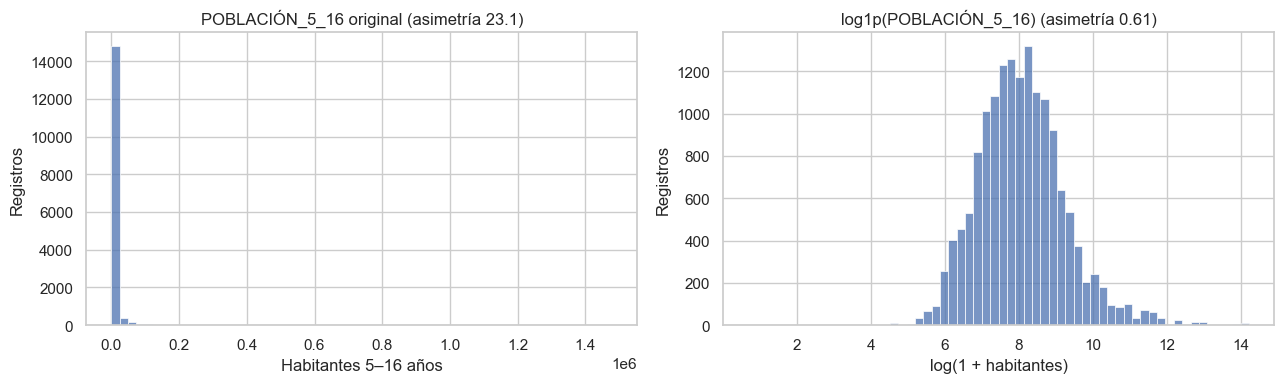

                        antes  después
POBLACIÓN_5_16          23.09     0.61
REPROBACIÓN_TRANSICIÓN   9.63     2.68
REPITENCIA_TRANSICIÓN    6.17     1.61
REPITENCIA_MEDIA         2.75     0.46
REPITENCIA_PRIMARIA      2.01     0.19
REPROBACIÓN_MEDIA        1.90    -0.17
REPROBACIÓN_PRIMARIA     1.86    -0.30
REPITENCIA               1.41     0.03
REPITENCIA_SECUNDARIA    1.24    -0.06


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["POBLACIÓN_5_16"], bins=60, ax=axes[0]); axes[0].set_title(f"POBLACIÓN_5_16 original (asimetría {df['POBLACIÓN_5_16'].skew():.1f})"); axes[0].set_xlabel("Habitantes 5–16 años"); axes[0].set_ylabel("Registros")
sns.histplot(np.log1p(df["POBLACIÓN_5_16"]), bins=60, ax=axes[1]); axes[1].set_title(f"log1p(POBLACIÓN_5_16) (asimetría {np.log1p(df['POBLACIÓN_5_16']).skew():.2f})"); axes[1].set_xlabel("log(1 + habitantes)"); axes[1].set_ylabel("Registros")
plt.tight_layout(); guardar("b_log_poblacion"); plt.show()

for c in A_LOG:
    df[f"LOG_{c}"] = np.log1p(df[c])  # log1p no "aprende" de los datos → no genera leakage
print(pd.DataFrame({"antes": df[A_LOG].skew(), "después": df[[f'LOG_{c}' for c in A_LOG]].skew().values}).round(2))

Se eligió **log1p** (y no Box-Cox/Yeo-Johnson) porque: (1) todas las variables son ≥ 0 y tienen ceros, que `log1p` maneja; (2) es una transformación fija que no se ajusta a los datos, así que puede aplicarse antes del split sin leakage; (3) es fácil de interpretar (cambios porcentuales). Se conservan las columnas originales para poder reportar en unidades reales.

## 7. Encoding de categóricas

In [12]:
# Ordinal: el orden es explícito, no alfabético
enc = OrdinalEncoder(categories=[ORDEN_TAMAÑO])
df["TAMAÑO_MUNICIPIO_ORD"] = enc.fit_transform(df[["TAMAÑO_MUNICIPIO"]]).astype(int)

# Nominales: One-Hot con drop_first=True para evitar la trampa de la variable dummy
dummies = pd.get_dummies(df[["REGION", "TIPO_ETC"]], drop_first=True, dtype=int)
df = pd.concat([df, dummies], axis=1)
print("Ordinal:", dict(zip(ORDEN_TAMAÑO, range(4))))
print("Dummies creadas:", dummies.columns.tolist())

Ordinal: {'Muy pequeño': 0, 'Pequeño': 1, 'Mediano': 2, 'Grande': 3}
Dummies creadas: ['REGION_Andina', 'REGION_Caribe', 'REGION_Insular', 'REGION_Orinoquía', 'REGION_Pacífica', 'TIPO_ETC_Municipal certificada']


- **Ordinal Encoding** para `TAMAÑO_MUNICIPIO`: tiene orden natural; codificarlo 0–3 conserva la información de "más grande que" en una sola columna.
- **One-Hot** para `REGION` y `TIPO_ETC`: son nominales (Caribe no es "mayor" que Andina). Un ordinal inventaría un orden falso. `drop_first=True` elimina una categoría de referencia (Amazonía / Departamental).
- `DEPARTAMENTO` y `MUNICIPIO` se mantienen como identificadores, no como features (1.100 municipios → alta cardinalidad).

## 8. Imputación y escalado: se ajustan **solo con train** (Pipeline)
Aquí se demuestra el preprocesamiento que usa la Fase C: un `ColumnTransformer` con KNN para las coberturas y la mediana para reprobación/repitencia. Se **ajusta (`fit`) únicamente con train** y luego solo se **aplica (`transform`)** a test, así que las filas de test nunca influyen en los valores imputados.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

MED_F = [f"LOG_{c}" if f"LOG_{c}" in df.columns else c for c in MED_COLS]  # la versión que usan los modelos
imputador = ColumnTransformer([("knn", KNNImputer(n_neighbors=5), COB_COLS), ("mediana", SimpleImputer(strategy="median"), MED_F)],
                              remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["ALTO_RIESGO_DESERCION"])
imp_train = imputador.fit_transform(train)   # aprende SOLO de train
imp_test = imputador.transform(test)         # test solo se transforma
assert imp_train.isna().sum().sum() == 0 and imp_test.isna().sum().sum() == 0
print(f"Nulos antes  → train: {train[COB_COLS + MED_F].isna().sum().sum()}, test: {test[COB_COLS + MED_F].isna().sum().sum()}")
print("Nulos después → 0 en ambos. Medianas aprendidas de train (primeras 3):", dict(zip(MED_F[:3], imputador.named_transformers_["mediana"].statistics_[:3].round(3))))

Nulos antes  → train: 1361, test: 286
Nulos después → 0 en ambos. Medianas aprendidas de train (primeras 3): {'REPROBACIÓN': np.float64(4.66), 'LOG_REPROBACIÓN_TRANSICIÓN': np.float64(0.0), 'LOG_REPROBACIÓN_PRIMARIA': np.float64(1.491)}


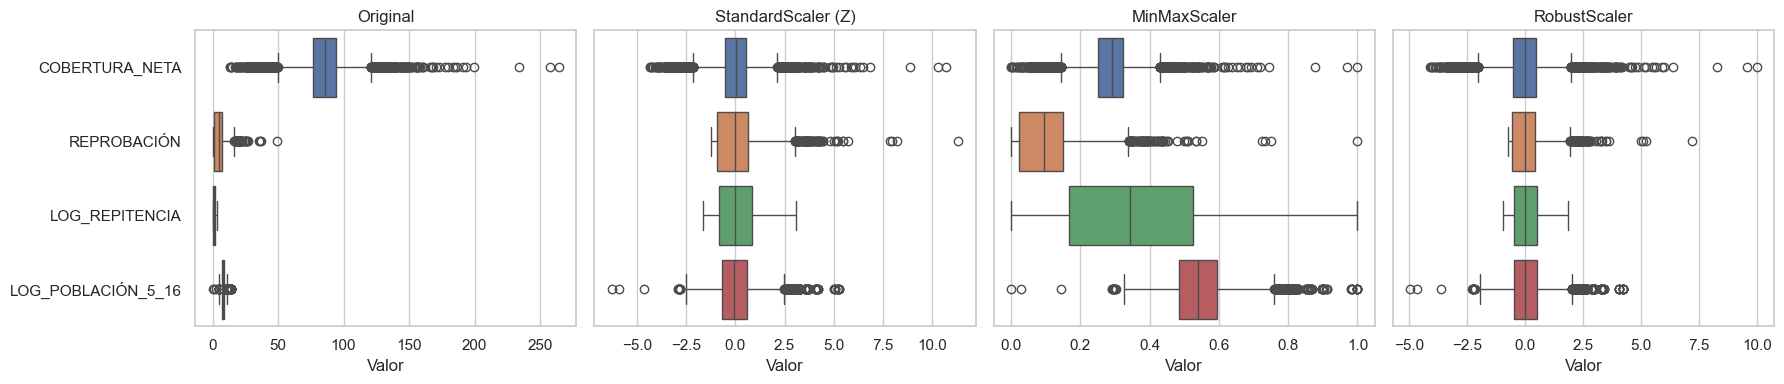

In [14]:
ESC_COLS = ["COBERTURA_NETA", "REPROBACIÓN", "LOG_REPITENCIA"]
base = imp_train[ESC_COLS].assign(LOG_POBLACIÓN_5_16=train["LOG_POBLACIÓN_5_16"].values)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (nombre, esc) in zip(axes, [("Original", None), ("StandardScaler (Z)", StandardScaler()), ("MinMaxScaler", MinMaxScaler()), ("RobustScaler", RobustScaler())]):
    datos = base if esc is None else pd.DataFrame(esc.fit_transform(base), columns=base.columns)
    sns.boxplot(data=datos, orient="h", ax=ax); ax.set_title(nombre); ax.set_xlabel("Valor")
plt.tight_layout(); guardar("b_escaladores"); plt.show()

**Elección: `StandardScaler` (Z-score)** para los modelos sensibles a la escala (Regresión logística, KNN, Regresión lineal, K-Means).
- Tras el `log1p` las variables quedan aproximadamente simétricas, que es el supuesto ideal del Z-score.
- `MinMaxScaler` comprime la mayoría de los datos en una franja estrecha cuando quedan outliers (coberturas > 200 %).
- `RobustScaler` sería la alternativa si no hubiéramos transformado; con log aplicado, la diferencia es mínima y el Z-score es el estándar para KNN/K-Means.

⚠️ **El parquet se guarda SIN escalar y SIN imputar las features.** El imputador y el escalador se ajustan dentro de un `Pipeline` en la Fase C **solo con el conjunto de entrenamiento**; hacerlo aquí con todo el dataset sería *data leakage* (prohibido por la guía).

## 9. Guardar datos limpios

In [15]:
df = df.sort_values(["AÑO", "CÓDIGO_MUNICIPIO"]).reset_index(drop=True)
df.to_parquet("datos_limpios.parquet", index=False)
chk = pd.read_parquet("datos_limpios.parquet")
PERMITIDOS = set(COB_COLS + MED_COLS + MED_F + ["DESERCIÓN_AÑO_ANTERIOR"])  # nulos que resuelve el Pipeline (o que no se imputan)
assert chk.shape == df.shape and set(chk.columns[chk.isna().any()]) <= PERMITIDOS
print("Guardado datos_limpios.parquet →", chk.shape)
print("Filas: crudo", len(raw), "→ limpio", len(chk))
chk.head()

Guardado datos_limpios.parquet → (15558, 60)
Filas: crudo 15707 → limpio 15558


,AÑO,CÓDIGO_MUNICIPIO,MUNICIPIO,CÓDIGO_DEPARTAMENTO,DEPARTAMENTO,CÓDIGO_ETC,ETC,POBLACIÓN_5_16,TASA_MATRICULACIÓN_5_16,COBERTURA_NETA,...,LOG_REPROBACIÓN_PRIMARIA,LOG_REPITENCIA,LOG_REPITENCIA_SECUNDARIA,TAMAÑO_MUNICIPIO_ORD,REGION_Andina,REGION_Caribe,REGION_Insular,REGION_Orinoquía,REGION_Pacífica,TIPO_ETC_Municipal certificada
0,2011,05001,Medellín,05,Antioquia,3759,Medellín,386466.0,108.73,108.5,...,0.000000,1.717395,2.132982,3,1,0,0,0,0,1
1,2011,05002,Abejorral,05,Antioquia,3758,Antioquia (ETC),4146.0,97.81,97.8,...,0.802002,0.636577,0.732368,1,1,0,0,0,0,0
2,2011,05004,Abriaquí,05,Antioquia,3758,Antioquia (ETC),483.0,88.61,88.6,...,0.904218,0.989541,1.169381,0,1,0,0,0,0,0
3,2011,05021,Alejandría,05,Antioquia,3758,Antioquia (ETC),702.0,118.52,118.5,...,1.150572,0.470004,0.000000,0,1,0,0,0,0,0
4,2011,05030,Amagá,05,Antioquia,3758,Antioquia (ETC),6631.0,78.65,78.7,...,2.045109,0.350657,0.647103,1,1,0,0,0,0,0


## Resumen del pipeline
| Paso | Acción | Filas |
|---|---|---|
| Crudo | CSV del MEN | 15.707 |
| Texto/llaves | Códigos rellenados con cero, nombres normalizados, separador de miles de POBLACIÓN 2021 corregido, filas `NACIONAL` eliminadas | 15.704 |
| Nulos | 2 columnas estructuralmente vacías eliminadas; objetivo nulo eliminado; población con la mediana del municipio; **KNN y mediana de las features → Pipeline ajustado solo con train** | 15.562 |
| Registros imposibles | Cobertura bruta = 0 % | 15.558 |
| Outliers | Conservados (justificado) | 15.558 |
| Features | Región, tamaño ordinal, tipo de ETC, deserción del año anterior, objetivo binario, 9 columnas `LOG_` y dummies | 59 columnas |

La imputación (KNN + mediana) y el escalado (StandardScaler) se ajustan en la Fase C, **después** del split, dentro de cada `Pipeline`.